In [24]:
import os
import pandas as pd
import numpy as np
import glasbey
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from dotenv import load_dotenv

load_dotenv()
random_seed = int(os.getenv("RANDOM_SEED"))
y_train_path = os.getenv("Y_TRAIN_TSV_PATH")
output_dir = os.getenv("OUTPUT_DIR")
color_palette_tsv_path = os.getenv("COLOR_PALETTE_TSV_PATH")

# Print configuration
print(f"y_train_path: {y_train_path}")
print(f"output_dir: {output_dir}")
print(f"random_seed: {random_seed}")
print(f"color_palette_tsv_path: {color_palette_tsv_path}")

y_train_path: /home/mariya/Data/pallas/nf-core-gexml-output-train/class/subtypes.tsv
output_dir: /home/mariya/Data/pallas/training
random_seed: 42
color_palette_tsv_path: /home/mariya/Data/pallas/colors.tsv


In [25]:
# Load y_train and get list of all unique classes
y_train = pd.read_csv(y_train_path, sep='\t', index_col=0)
unique_classes = y_train['class'].unique()
unique_classes

array(['AML, KMT2A-r', 'B-ALL, PAX5alt', 'B-ALL, PAX5 P80R',
       'B-ALL, high hyperdiploid', 'B-ALL, TCF3::PBX1',
       'AML, RUNX1::RUNX1T1', 'B-ALL, hypodiploid', 'AML, NUP98-r',
       'AML, CBFB::MYH11', 'B-ALL, KMT2A-r', 'B-ALL, BCR::ABL1-like',
       'AML, CBFA2T3::GLIS2', 'B-ALL, ETV6::RUNX1', 'B-ALL, iAMP21',
       'AML, NPM1alt', 'T-ALL', 'B-ALL, DUX4-r',
       'B-ALL, ETV6::RUNX1-like', 'AML, APL-PML::RARA', 'B-ALL, ZNF384-r',
       'AML, CEBPAalt', 'B-ALL, NUTM1-r', 'B-ALL, BCR::ABL1',
       'B-ALL, MEF2D-r', 'B-ALL, IKZF1 N159Y', 'B-ALL, MYC-r',
       'B-ALL, HLF-r', 'Non-leukemic'], dtype=object)

In [26]:
# Get all AML subtypes, all items that start with "AML"
aml = unique_classes[[cls.startswith("AML") for cls in unique_classes]]
aml = np.append(aml, "AML, other")
aml

array(['AML, KMT2A-r', 'AML, RUNX1::RUNX1T1', 'AML, NUP98-r',
       'AML, CBFB::MYH11', 'AML, CBFA2T3::GLIS2', 'AML, NPM1alt',
       'AML, APL-PML::RARA', 'AML, CEBPAalt', 'AML, other'], dtype=object)

In [27]:
ball = unique_classes[[cls.startswith("B-ALL") for cls in unique_classes]]
ball = np.append(ball, "B-ALL, other")
ball

array(['B-ALL, PAX5alt', 'B-ALL, PAX5 P80R', 'B-ALL, high hyperdiploid',
       'B-ALL, TCF3::PBX1', 'B-ALL, hypodiploid', 'B-ALL, KMT2A-r',
       'B-ALL, BCR::ABL1-like', 'B-ALL, ETV6::RUNX1', 'B-ALL, iAMP21',
       'B-ALL, DUX4-r', 'B-ALL, ETV6::RUNX1-like', 'B-ALL, ZNF384-r',
       'B-ALL, NUTM1-r', 'B-ALL, BCR::ABL1', 'B-ALL, MEF2D-r',
       'B-ALL, IKZF1 N159Y', 'B-ALL, MYC-r', 'B-ALL, HLF-r',
       'B-ALL, other'], dtype=object)

In [28]:
def show_palette(palette):
    fig, ax = plt.subplots(figsize=(10, 6))
    for i, color in enumerate(palette):
        ax.add_patch(Rectangle((i, 0), 1, 1, color=color))
    ax.set_xlim(0, len(palette))
    ax.set_ylim(0, 1)
    ax.axis('off')
    plt.show()

In [29]:
block_shape = [len(aml), len(ball), 1, 1]
block_shape

[9, 19, 1, 1]

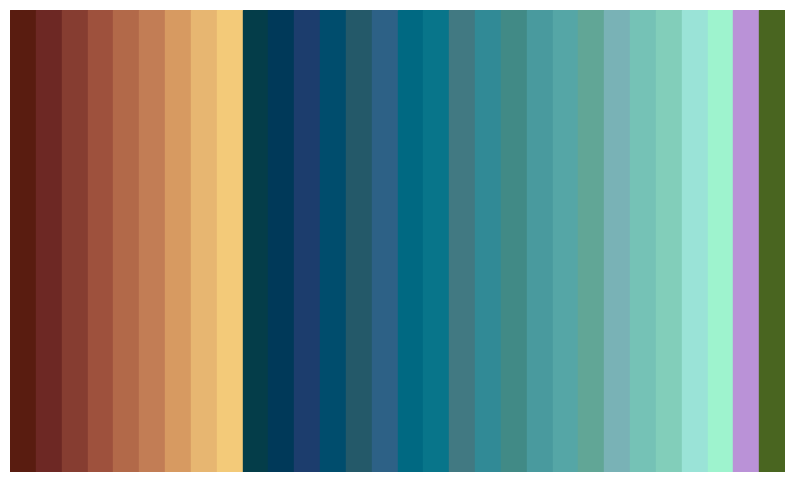

In [30]:
palette = glasbey.create_block_palette(block_shape,lightness_bounds=(15, 90),
        chroma_bounds=(0, 40), optimize_palette=True)
show_palette(palette)

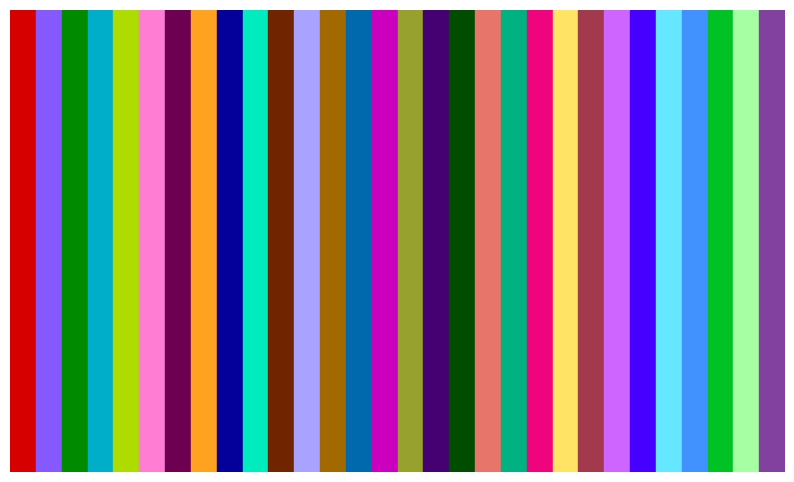

In [31]:
palette = glasbey.create_palette(palette_size=len(aml) + len(ball) + 2,
                                 chroma_bounds=(50, 100),
                                 optimize_palette=True)

show_palette(palette)


In [32]:
# Map each color in palette to a class in aml and ball
pal_dict = {}
for i, cls in enumerate(aml):
    pal_dict[cls] = palette[i]
for i, cls in enumerate(ball):
    pal_dict[cls] = palette[i + len(aml)]
pal_dict["T-ALL"] = palette[-2]
pal_dict["Non-leukemic"] = palette[-1]
pal_dict

{'AML, KMT2A-r': '#d70000',
 'AML, RUNX1::RUNX1T1': '#8659ff',
 'AML, NUP98-r': '#008a00',
 'AML, CBFB::MYH11': '#00aeca',
 'AML, CBFA2T3::GLIS2': '#aedb00',
 'AML, NPM1alt': '#ff7dd2',
 'AML, APL-PML::RARA': '#6d0051',
 'AML, CEBPAalt': '#ffa220',
 'AML, other': '#04009a',
 'B-ALL, PAX5alt': '#00ebbe',
 'B-ALL, PAX5 P80R': '#712400',
 'B-ALL, high hyperdiploid': '#aaa2ff',
 'B-ALL, TCF3::PBX1': '#a26900',
 'B-ALL, hypodiploid': '#0069ae',
 'B-ALL, KMT2A-r': '#ca00be',
 'B-ALL, BCR::ABL1-like': '#96a22d',
 'B-ALL, ETV6::RUNX1': '#450071',
 'B-ALL, iAMP21': '#004d00',
 'B-ALL, DUX4-r': '#e77569',
 'B-ALL, ETV6::RUNX1-like': '#00b282',
 'B-ALL, ZNF384-r': '#ef047d',
 'B-ALL, NUTM1-r': '#ffe365',
 'B-ALL, BCR::ABL1': '#a2394d',
 'B-ALL, MEF2D-r': '#ce65ff',
 'B-ALL, IKZF1 N159Y': '#4500ff',
 'B-ALL, MYC-r': '#65e7ff',
 'B-ALL, HLF-r': '#4192ff',
 'B-ALL, other': '#00c224',
 'T-ALL': '#a6ffa2',
 'Non-leukemic': '#82419e'}

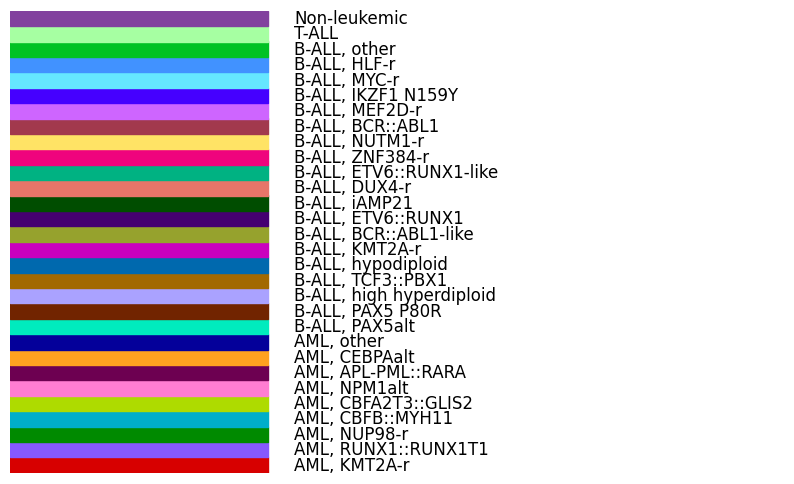

In [33]:
# Visualize pal_dict colors with labels
fig, ax = plt.subplots(figsize=(10, 6))
for i, (cls, color) in enumerate(pal_dict.items()):
    ax.add_patch(Rectangle((0, i), 1, 1, color=color))
    ax.text(1.1, i + 0.5, cls, va='center', fontsize=12)
ax.set_xlim(0, 3)
ax.set_ylim(0, len(pal_dict))
ax.axis('off')
plt.show()


In [34]:
# Save palette as a TSV file without header
pal_df = pd.DataFrame.from_dict(pal_dict, orient='index', columns=['color'])
pal_df.index.name = 'class'
pal_df.to_csv(color_palette_tsv_path, sep='\t', header=False)